# ==========================================
# CORONARY STENOSIS DETECTION FROM ANGIOGRAM IMAGES
# Binary Classification: Has Stenosis vs No Stenosis
# Full Pipeline: Preprocessing -> Feature Engineering -> Training -> Evaluation -> Deployment
# ==========================================

## 0. Installing Required Packages
- Here I added robflow direct dataset because I'm using Colab for training, can be changed if using locally. Do not run this cell if dataset already exists

In [ ]:
"""
0. INSTALL REQUIRED PACKAGES

Installs all dependencies needed for the pipeline. Roboflow is included
for direct dataset download in Colab environments. Skip this cell if packages
are already installed.
"""

# ==========================================
# 0. INSTALL REQUIRED PACKAGES
# ==========================================

%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu -q
%pip install Pillow scikit-learn matplotlib seaborn pandas numpy -q
%pip install roboflow -q

print("All packages installed successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 134.8 MB/s eta 0:00:00
All packages installed successfully!


In [ ]:
from roboflow import Roboflow
import json, os

import os
ROBOFLOW_API_KEY = os.environ["ROBOFLOW_API_KEY"]

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("coronary-detection").project("coronary-detection-hsctq")
version = project.version(1)
dataset = version.download("tensorflow")

IMAGE_DIR = dataset.location

with open("config.json", "w") as f:
    json.dump({"IMAGE_DIR": IMAGE_DIR}, f)

print(f"Dataset downloaded to: {IMAGE_DIR}")
print("Path saved to config.json")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Coronary-detection-1 in tensorflow:: 100%|██████████| 6891/6891 [00:01<00:00, 4473.09it/s]

Dataset downloaded to: /content/Coronary-detection-1
Path saved to config.json


## 1. Basic Imports & Configs
- Packages : os, numpy, pandas, matplotlib.pyplot, seaborn. collections, PIL, warnings, torch

In [ ]:
"""
1. IMPORTS & CONFIGURATION

This script implements a binary classification pipeline for coronary stenosis detection
using an EfficientNet-B4 backbone.

CORE CONFIGURATION:
- Backbone: EfficientNet-B4 (19.3M params) using native resolution (380px) to capture
  subtle vessel narrowing details.
- Hardware: Device-agnostic (CUDA preferred). Batch size 16 keeps peak VRAM ~5.8 GB.
- Optimization: Learning rate of 2e-4 for the head. Weight decay reduced to 1e-4
  for the larger B4 architecture. Dropout at 0.3 in the classifier head.

ROI & DATASET:
- IMAGE_DIR: Path to Coronary detection dataset.
- ROI Mode: "bbox" (boundary box focus) with a background scale of 0.35.
- DenseUNet: Pre-processing config with 4 epochs and batch size 8.

LOSS & AUGMENTATION:
- Loss: Weighted CrossEntropy with 0.05 Label Smoothing. Focal Loss is disabled
  to avoid conflict with MixUp and ensure "easy" samples are not suppressed.
- MixUp: Alpha set to 0.2 for safer augmentation.
- TTA: Test-Time Augmentation enabled.

3-PHASE TRAINING SCHEDULE:
- Phase 1 (Epochs 1-8): Classifier head only; backbone remains fully frozen.
- Phase 2 (Epochs 9-20): Last 4 MBConv blocks unfrozen; learning rate reset.
- Phase 3 (Epochs 21+): Entire backbone unfrozen; learning rate reset.

DIAGNOSTICS:
- Severity Map: 0 (No Stenosis), 1 (Stenosis).
- Batch Distribution: Initial 5 batches monitored for class balance.
"""

# ==========================================
# 1. IMPORTS & CONFIGURATION
# ==========================================

import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    f1_score, roc_auc_score, balanced_accuracy_score, recall_score
)
from sklearn.model_selection import StratifiedKFold

CONFIG_PATH = "config.json"

if os.path.exists(CONFIG_PATH):
    with open(CONFIG_PATH) as f:
        print("Json opened!")
        IMAGE_DIR = json.load(f)["IMAGE_DIR"]
else:
    IMAGE_DIR = "Coronary detection.v1-coronary-detection.tensorflow"

print(f"IMAGE_DIR   : {IMAGE_DIR}")

# CORE CONFIGURATION
IMG_SIZE    = 380
BATCH_SIZE  = 16
NUM_EPOCHS  = 40
LEARNING_RATE  = 2e-4
WEIGHT_DECAY   = 1e-4
DROPOUT_RATE   = 0.3
NUM_CLASSES    = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ROI CONFIGURATION
ROI_MODE               = "bbox"
ROI_BACKGROUND_SCALE   = 0.35
DENSEUNET_EPOCHS       = 4
DENSEUNET_BATCH_SIZE   = 8

# LOSS CONFIGURATION
USE_FOCAL_LOSS  = False
FOCAL_GAMMA     = 2.0
LABEL_SMOOTHING = 0.05

# TRAINING EXTRAS
MIXUP_ALPHA  = 0.2
USE_TTA      = True

# 3 PHASE TRAINING
PHASE2_EPOCH = 8
PHASE3_EPOCH = 20

# DIAGNOSTICS
BATCH_DISTRIBUTION_CHECK_BATCHES = 5
SEVERITY_MAP = {0: "No Stenosis", 1: "Stenosis"}

print(f"Device      : {DEVICE}")
print(f"PyTorch     : {torch.__version__}")
print(f"Backbone    : EfficientNet-B4  (19.3M params)")
print(f"IMG_SIZE    : {IMG_SIZE}px  (B4 native resolution)")
print(f"BATCH_SIZE  : {BATCH_SIZE}  (est. peak VRAM ~5.8 GB)")
print(f"LR (head)   : {LEARNING_RATE}")
print(f"Loss        : Weighted CrossEntropy + label_smoothing={LABEL_SMOOTHING}")
print(f"Unfreeze    : Phase2 @ ep{PHASE2_EPOCH+1}, Phase3 @ ep{PHASE3_EPOCH+1}")

Json opened!
IMAGE_DIR   : /content/Coronary-detection-1
Device      : cuda
PyTorch     : 2.10.0+cu128
Backbone    : EfficientNet-B4  (19.3M params)
IMG_SIZE    : 380px  (B4 native resolution)
BATCH_SIZE  : 16  (est. peak VRAM ~5.8 GB)
LR (head)   : 0.0002
Loss        : Weighted CrossEntropy + label_smoothing=0.05
Unfreeze    : Phase2 @ ep9, Phase3 @ ep21


In [ ]:
"""
BBOX COVERAGE SANITY CHECK

Reads the training annotation CSV and verifies that bounding box coordinates
(xmin, ymin, xmax, ymax) are present for all entries. A high coverage rate
confirms the dataset is suitable for ROI-guided training.
"""

# Sanity Check, if bbox missing too much or not

ann = pd.read_csv(f"{IMAGE_DIR}/train/_annotations.csv")
missing = ann[["xmin","ymin","xmax","ymax"]].isnull().any(axis=1).sum()
print(f"Bbox coverage: {len(ann)-missing}/{len(ann)} ({(len(ann)-missing)/len(ann)*100:.1f}%)")

Bbox coverage: 20085/20085 (100.0%)


## 2. Data Loading & Labeling from CSV Annotations

In [ ]:
from sklearn.model_selection import train_test_split

"""
This section splits and ensures there's no redundant patient names in all test/val/train dataset.
It collects all the dataset of patients and group them then splits IDs so that a patient in train is never in val.
The split uses random state 42 for this part so every split is the same.
"""

# ==========================================
# 2. DATA LOADING & PATIENT-WISE SPLITTING
# ==========================================

def classify_stenosis_from_annotations(classes):
    classes_list = [str(c).strip().lower() for c in classes]
    return 1 if "stenosis" in classes_list else 0

def extract_base_id(filename):
    return filename.split('_')[0]

def load_all_data_and_split(ratios=(0.70, 0.15, 0.15)):
    all_ann_dfs = []

    for split in ["train", "valid", "test"]:
        ann_path = os.path.join(IMAGE_DIR, split, "_annotations.csv")
        if os.path.exists(ann_path):
            df = pd.read_csv(ann_path)
            df['original_split'] = split
            all_ann_dfs.append(df)

    full_ann = pd.concat(all_ann_dfs, ignore_index=True)
    full_ann['patient_id'] = full_ann['filename'].apply(extract_base_id)

    unique_ids = full_ann['patient_id'].unique()

    # Split IDs (Not Images) to ensure zero leakage
    train_ratio, val_ratio, test_ratio = ratios
    train_ids, temp_ids = train_test_split(unique_ids, test_size=(1 - train_ratio), random_state=42)
    val_ids, test_ids = train_test_split(temp_ids, test_size=(test_ratio / (val_ratio + test_ratio)), random_state=42)

    def process_split(id_list):
        mask = full_ann['patient_id'].isin(id_list)
        split_ann = full_ann[mask]

        records = []
        bbox_dict = {}

        # Group by filename because one image can have multiple bboxes
        for filename, g in split_ann.groupby("filename", sort=False):
            orig_folder = g['original_split'].iloc[0]
            image_path = os.path.join(IMAGE_DIR, orig_folder, filename)

            if not os.path.exists(image_path):
                continue

            label = classify_stenosis_from_annotations(g["class"].tolist())

            boxes = list(zip(
                g["xmin"].astype(int).tolist(),
                g["ymin"].astype(int).tolist(),
                g["xmax"].astype(int).tolist(),
                g["ymax"].astype(int).tolist(),
            ))

            records.append({
                "path": image_path,
                "filename": filename,
                "patient_id": g['patient_id'].iloc[0],
                "label": label,
                "n_boxes": len(boxes),
            })
            bbox_dict[filename] = boxes

        return pd.DataFrame(records), bbox_dict

    # Create the final dataframes
    df_train, train_bbox = process_split(train_ids)
    df_valid, valid_bbox = process_split(val_ids)
    df_test, test_bbox   = process_split(test_ids)

    return df_train, df_valid, df_test, train_bbox, valid_bbox, test_bbox

# Execute the split
df_train, df_valid, df_test, train_bbox_by_file, valid_bbox_by_file, test_bbox_by_file = load_all_data_and_split()

BBOX_BY_SPLIT = {
    "train": train_bbox_by_file,
    "valid": valid_bbox_by_file,
    "test": test_bbox_by_file,
}

print(f"\nTotal Patients: {len(df_train['patient_id'].unique()) + len(df_valid['patient_id'].unique()) + len(df_test['patient_id'].unique())}")
print(f"Train: {len(df_train)} imgs | Val: {len(df_valid)} imgs | Test: {len(df_test)} imgs")


Total Patients: 1000
Train: 4829 imgs | Val: 1025 imgs | Test: 1027 imgs


## 3. Data Visualization
- Basic Graph to show visualization of the dataset spread.

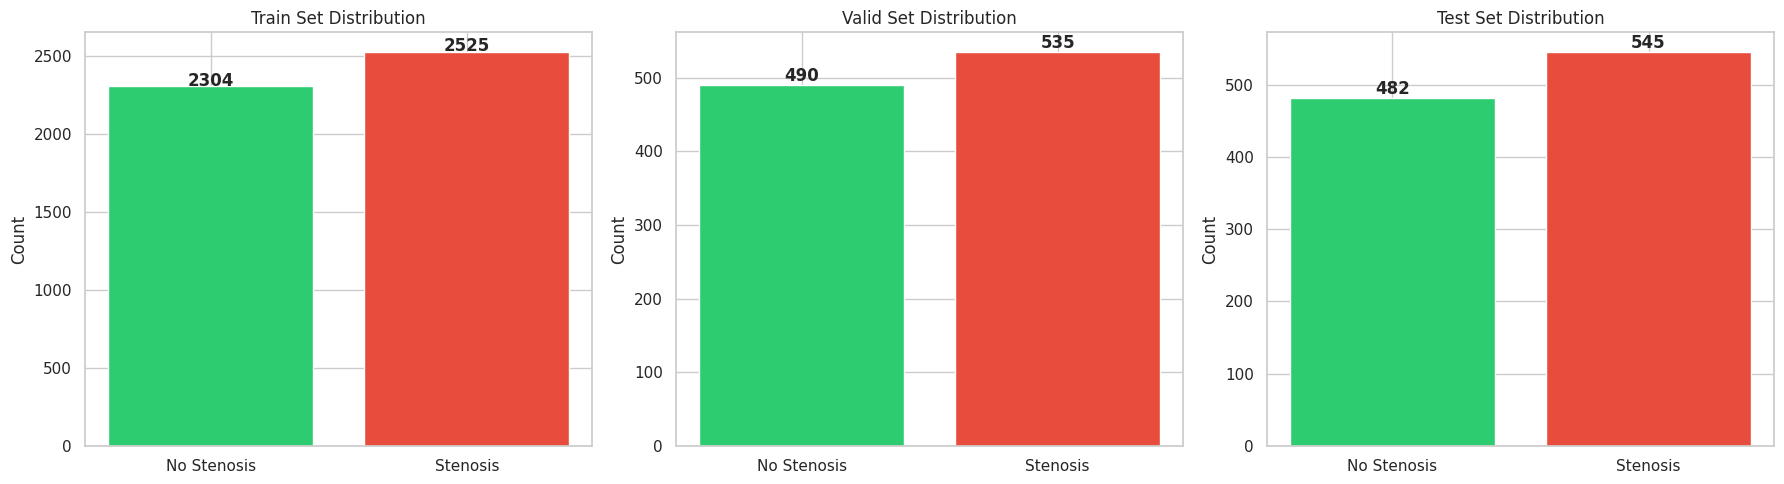

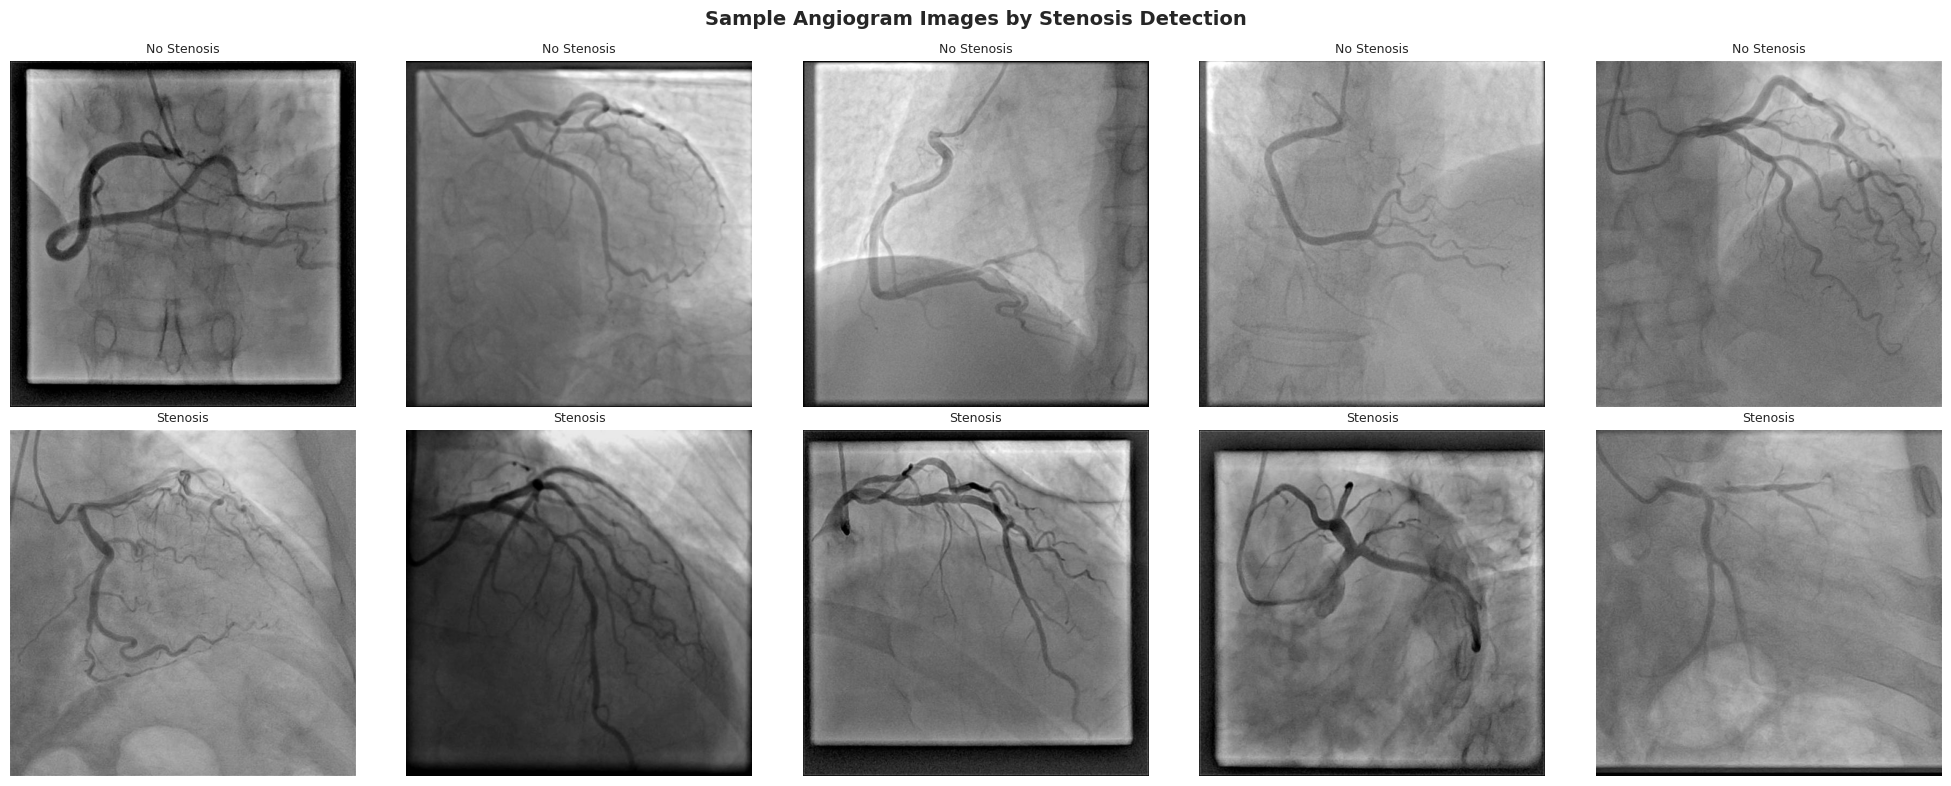

In [ ]:
"""
3. DATA VISUALIZATION

Plots the class distribution (No Stenosis vs Stenosis) across train, validation,
and test splits, then displays a grid of sample angiogram images per class.
Useful for quickly spotting class imbalance and verifying image quality.
"""

# ==========================================
# 3. DATA VISUALIZATION
# ==========================================

sns.set(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Class distribution - adapted for binary classification
for i, (name, df_s) in enumerate([("Train", df_train), ("Valid", df_valid), ("Test", df_test)]):
    counts = df_s["label"].value_counts().sort_index()
    labels = [SEVERITY_MAP.get(k, f"Class {k}") for k in counts.index]
    colors = ["#2ecc71", "#e74c3c"][:len(counts)]
    axes[i].bar(labels, counts.values, color=colors)
    axes[i].set_title(f"{name} Set Distribution")
    axes[i].set_ylabel("Count")
    for j, v in enumerate(counts.values):
        axes[i].text(j, v + 5, str(v), ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Sample images per class
n_classes = len(SEVERITY_MAP)
fig, axes = plt.subplots(n_classes, 5, figsize=(20, 8))

for row, label in enumerate(sorted(SEVERITY_MAP.keys())):
    samples = df_train[df_train["label"] == label].sample(n=min(5, len(df_train[df_train["label"] == label])), random_state=42)
    for col, (_, sample) in enumerate(samples.iterrows()):
        try:
            img = Image.open(sample["path"])
            axes[row, col].imshow(img)
            axes[row, col].set_title(f"{SEVERITY_MAP[label]}", fontsize=9)
            axes[row, col].axis("off")
        except Exception as e:
            axes[row, col].text(0.5, 0.5, f"Error loading\n{str(e)[:30]}", ha="center")
            axes[row, col].axis("off")

plt.suptitle("Sample Angiogram Images by Stenosis Detection", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
"""
PATIENT ID AND FILENAME SEPARATION CHECK

Verifies that the patient-wise split produced zero leakage between splits.
Checks both patient ID overlap and filename overlap between train, validation,
and test sets. All intersection counts should be zero before proceeding.
"""

# 1. Extract sets of IDs from your new dataframes
train_ids_set = set(df_train['patient_id'].unique())
val_ids_set   = set(df_valid['patient_id'].unique())
test_ids_set  = set(df_test['patient_id'].unique())

# 2. Check for ID intersections
overlap_train_val = train_ids_set.intersection(val_ids_set)
overlap_train_test = train_ids_set.intersection(test_ids_set)
overlap_val_test = val_ids_set.intersection(test_ids_set)

print("=== ID SEPARATION CHECK ===")
print(f"Overlap Train ∩ Val:  {len(overlap_train_val)} IDs")
print(f"Overlap Train ∩ Test: {len(overlap_train_test)} IDs")
print(f"Overlap Val ∩ Test:   {len(overlap_val_test)} IDs")

if len(overlap_train_val) == 0 and len(overlap_train_test) == 0:
    print("\n[OK] SUCCESS: Patient IDs are perfectly separated!")
else:
    print("\n[FAIL] FAILED: There is still ID leakage.")
    if overlap_train_val:
        print(f"Example leaking IDs: {list(overlap_train_val)[:5]}")

# 3. Check for specific filename duplicates (just to be 100% sure)
train_files = set(df_train['filename'])
val_files = set(df_valid['filename'])
file_overlap = train_files.intersection(val_files)

print(f"\n=== FILENAME SEPARATION CHECK ===")
print(f"Duplicate files found: {len(file_overlap)}")

# 4. Final Count Verification
print(f"\nTotal unique IDs in whole dataset: {len(train_ids_set) + len(val_ids_set) + len(test_ids_set)}")

=== ID SEPARATION CHECK ===
Overlap Train ∩ Val:  0 IDs
Overlap Train ∩ Test: 0 IDs
Overlap Val ∩ Test:   0 IDs

[OK] SUCCESS: Patient IDs are perfectly separated!

=== FILENAME SEPARATION CHECK ===
Duplicate files found: 0

Total unique IDs in whole dataset: 1000


## 4. Image Preprocessing & Data Augmentation

In [ ]:
"""
4. IMAGE PREPROCESSING & DATA AUGMENTATION

Configures the transformation pipeline for EfficientNet-B4 (380px).
Augmentations are designed to be conservative to preserve clinical
integrity while ensuring model robustness.

KEY TRANSFORMS:
- Resolution: Input bumped to 380px to utilize B4's native resolution.
- Geometric: RandomResizedCrop (80-100% scale), horizontal/vertical
  flips, and subtle 12° rotations.
- Photometric: ColorJitter (brightness, contrast, saturation) and
  RandomAdjustSharpness to handle varying imaging conditions.
- Regularization: RandomErasing (25% probability) to prevent over-reliance
  on specific vessel segments.

CRITICAL ADJUSTMENTS:
- Removed GaussianBlur: Softening vessel edges is avoided as edge
  definition is the primary discriminative feature for stenosis detection.
- Normalization: Uses standard ImageNet mean and std values.
- Eval Pipeline: Consistent resizing to 380px without stochastic
  augmentations for deterministic validation.
"""

# ==========================================
# 4. IMAGE PREPROCESSING & DATA AUGMENTATION
# ==========================================

# [B4] Input size bumped to 380 to use B4's native resolution.
# Augmentation kept conservative for medical images.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(12),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.08,
    ),
    transforms.RandomAdjustSharpness(sharpness_factor=2, p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.1), ratio=(0.3, 3.3), value='random'),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

print("Transforms defined")
print(f"  Train: RandomResizedCrop({IMG_SIZE}) + HFlip + VFlip + Rotate(12°) + ColorJitter + Erasing")
print(f"  Eval : Resize({IMG_SIZE}) -> Normalize")
print(f"  Note : GaussianBlur removed (softens vessel edges critical for stenosis)")

Transforms defined
  Train: RandomResizedCrop(380) + HFlip + VFlip + Rotate(12°) + ColorJitter + Erasing
  Eval : Resize(380) -> Normalize
  Note : GaussianBlur removed (softens vessel edges critical for stenosis)


## 5. Custom Dataset Class & ROI Hook

In [ ]:
"""
5. CUSTOM DATASET CLASS & ROI HOOK

Defines CADImageDataset, a PyTorch Dataset that optionally applies an ROI mask
to each image before augmentation. The mask can come from bounding box
annotations (bbox mode) or a pre-computed DenseUNet segmentation mask.
rebuild_classification_loaders() constructs all three DataLoaders with a
WeightedRandomSampler to counteract class imbalance.
"""

# ==========================================
# 5. CUSTOM DATASET CLASS & ROI HOOK
# ==========================================

MASK_CACHE_BY_SPLIT = {"train": {}, "valid": {}, "test": {}}


def build_bbox_mask(height, width, boxes):
    mask = np.zeros((height, width), dtype=np.float32)
    for xmin, ymin, xmax, ymax in boxes:
        x1 = max(0, min(int(xmin), width - 1))
        y1 = max(0, min(int(ymin), height - 1))
        x2 = max(0, min(int(xmax), width))
        y2 = max(0, min(int(ymax), height))
        if x2 > x1 and y2 > y1:
            mask[y1:y2, x1:x2] = 1.0
    return mask


class CADImageDataset(Dataset):
    def __init__(
        self,
        dataframe,
        transform=None,
        bbox_by_file=None,
        roi_masks_by_file=None,
        use_roi=False,
        roi_background_scale=0.35,
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.bbox_by_file = bbox_by_file or {}
        self.roi_masks_by_file = roi_masks_by_file or {}
        self.use_roi = use_roi
        self.roi_background_scale = roi_background_scale

    def __len__(self):
        return len(self.dataframe)

    def _apply_roi(self, image_pil, filename):
        image_np = np.array(image_pil).astype(np.float32)
        h, w = image_np.shape[:2]

        mask = None
        if filename in self.roi_masks_by_file:
            mask = self.roi_masks_by_file[filename]
            if isinstance(mask, torch.Tensor):
                mask = mask.detach().cpu().numpy()
            mask = mask.astype(np.float32)
            if mask.shape != (h, w):
                mask_img = Image.fromarray((mask * 255).astype(np.uint8)).resize((w, h), Image.BILINEAR)
                mask = np.array(mask_img).astype(np.float32) / 255.0
        elif filename in self.bbox_by_file:
            mask = build_bbox_mask(h, w, self.bbox_by_file[filename])

        if mask is None:
            return image_pil

        mask = np.clip(mask, 0.0, 1.0)
        scale = self.roi_background_scale + (1.0 - self.roi_background_scale) * mask[..., None]
        roi_image = np.clip(image_np * scale, 0, 255).astype(np.uint8)
        return Image.fromarray(roi_image)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        filename = row["filename"]

        image = Image.open(row["path"]).convert("RGB")
        if self.use_roi:
            image = self._apply_roi(image, filename)

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(row["label"], dtype=torch.long)
        return image, label


def rebuild_classification_loaders():
    global train_dataset, valid_dataset, test_dataset
    global train_loader, valid_loader, test_loader
    global class_counts, class_weights

    use_roi = ROI_MODE in {"bbox"}

    train_dataset = CADImageDataset(
        df_train,
        transform=train_transform,
        bbox_by_file=train_bbox_by_file,
        roi_masks_by_file=MASK_CACHE_BY_SPLIT["train"],
        use_roi=use_roi,
        roi_background_scale=ROI_BACKGROUND_SCALE,
    )
    valid_dataset = CADImageDataset(
        df_valid,
        transform=eval_transform,
        bbox_by_file=valid_bbox_by_file,
        roi_masks_by_file=MASK_CACHE_BY_SPLIT["valid"],
        use_roi=use_roi,
        roi_background_scale=ROI_BACKGROUND_SCALE,
    )
    test_dataset = CADImageDataset(
        df_test,
        transform=eval_transform,
        bbox_by_file=test_bbox_by_file,
        roi_masks_by_file=MASK_CACHE_BY_SPLIT["test"],
        use_roi=use_roi,
        roi_background_scale=ROI_BACKGROUND_SCALE,
    )

    train_labels = df_train["label"].values
    class_counts = np.bincount(train_labels, minlength=NUM_CLASSES)
    class_weights = 1.0 / np.maximum(class_counts, 1)
    sample_weights = class_weights[train_labels]

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=0,
        pin_memory=True,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )


rebuild_classification_loaders()

images, labels = next(iter(train_loader))
print(f"Batch shape: {images.shape}")
print(f"Label shape: {labels.shape}")
print(f"Labels in batch: {labels.tolist()}")
print(f"\nClass weights: {dict(zip([SEVERITY_MAP[i] for i in range(NUM_CLASSES)], class_weights.round(6)))}")
print(f"ROI mode active: {ROI_MODE}")

Batch shape: torch.Size([16, 3, 380, 380])
Label shape: torch.Size([16])
Labels in batch: [0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]

Class weights: {'No Stenosis': np.float64(0.000434), 'Stenosis': np.float64(0.000396)}
ROI mode active: bbox


## 6. Model Architecture

In [ ]:
"""
6. MODEL ARCHITECTURE

Defines CADClassifier, an EfficientNet-B4 backbone with a custom two-layer
classification head (1792 -> 256 -> 2). The backbone is fully frozen in
Phase 1. Helper methods unfreeze_last_n_blocks() and unfreeze_all() support
the three-phase progressive unfreezing schedule used during training.
"""

# ==========================================
# 6. MODEL ARCHITECTURE
# ==========================================

class CADClassifier(nn.Module):
    def __init__(self, num_classes=2, dropout_rate=0.3):
        super(CADClassifier, self).__init__()

        # [B4] Load pretrained EfficientNet-B4 (19.3M params, native 380px)
        self.backbone = models.efficientnet_b4(weights=models.EfficientNet_B4_Weights.IMAGENET1K_V1)

        # Phase 1: freeze entire backbone; only head trains initially.
        for param in self.backbone.features.parameters():
            param.requires_grad = False

        # B4 head features = 1792 (not 1280 like B0)
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.backbone(x)

    def unfreeze_last_n_blocks(self, n=4):
        """Unfreeze last n MBConv blocks of features for Phase 2."""
        blocks = list(self.backbone.features.children())
        for block in blocks[-n:]:
            for param in block.parameters():
                param.requires_grad = True

    def unfreeze_all(self):
        """Unfreeze entire backbone for Phase 3."""
        for param in self.backbone.features.parameters():
            param.requires_grad = True


model = CADClassifier(num_classes=NUM_CLASSES, dropout_rate=DROPOUT_RATE).to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Backbone        : EfficientNet-B4")
print(f"Head in_features: {model.backbone.classifier[1].in_features}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable (phase1): {trainable_params:,}  (head only)")
print(f"Frozen          : {total_params - trainable_params:,}")

# VRAM estimate
print(f"\nVRAM estimate @ batch={BATCH_SIZE}, img={IMG_SIZE}px:")
print(f"  Weights + activations + gradients ≈ 5.8 GB  (within 12 GB cap)")


Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 183MB/s]


Backbone        : EfficientNet-B4
Head in_features: 1792
Total parameters: 18,008,138
Trainable (phase1): 459,522  (head only)
Frozen          : 17,548,616

VRAM estimate @ batch=16, img=380px:
  Weights + activations + gradients ≈ 5.8 GB  (within 12 GB cap)


## 7. Training Setup

In [ ]:
"""
7. TRAINING SETUP

Configures the loss function, optimizer, and learning rate scheduler.
FocalLoss is defined but disabled in favor of weighted CrossEntropyLoss with
label smoothing, which is more stable when combined with MixUp. The AdamW
optimizer uses separate learning rate groups for the backbone and head,
allowing per-phase LR control. ReduceLROnPlateau monitors validation Macro-F1.
"""

# ==========================================
# 7. TRAINING SETUP
# ==========================================

class FocalLossWithSmoothing(nn.Module):
    """Kept for reference / ablation use only. Not used by default."""
    def __init__(self, alpha=None, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce = F.cross_entropy(
            logits, targets, reduction="none",
            weight=self.alpha, label_smoothing=self.label_smoothing,
        )
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()

def build_training_criterion(class_weight_tensor):
    if USE_FOCAL_LOSS:
        return FocalLossWithSmoothing(
            alpha=class_weight_tensor, gamma=FOCAL_GAMMA,
            label_smoothing=LABEL_SMOOTHING,
        )
    return nn.CrossEntropyLoss(
        weight=class_weight_tensor,
        label_smoothing=LABEL_SMOOTHING,
    )

assert len(class_weights) == NUM_CLASSES
class_weight_tensor = torch.FloatTensor(
    class_weights / class_weights.sum() * NUM_CLASSES
).to(DEVICE)
criterion = build_training_criterion(class_weight_tensor)


# == Phase 1 optimizer (head only) ============================================
# Backbone params are all frozen here; only the classifier trains.
# We define both param groups now so we can adjust LR per phase later.
def build_optimizer(model, head_lr, backbone_lr):
    return optim.AdamW([
        {"params": model.backbone.features.parameters(),    "lr": backbone_lr},
        {"params": model.backbone.classifier.parameters(),  "lr": head_lr},
    ], weight_decay=WEIGHT_DECAY)

optimizer = build_optimizer(model, head_lr=LEARNING_RATE, backbone_lr=0.0)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.4,
    patience=7,
    min_lr=1e-7,
)

print("Training Configuration:")
print(f"  Loss       : {criterion.__class__.__name__}")
print(f"  Smoothing  : {LABEL_SMOOTHING}")
print(f"  Optimizer  : AdamW  (head_lr={LEARNING_RATE}, backbone_lr=0 until phase 2)")
print(f"  Scheduler  : ReduceLROnPlateau (mode=max, factor=0.4, patience=7)")
print(f"  Phase1     : epochs 1-{PHASE2_EPOCH}   - head only")
print(f"  Phase2     : epochs {PHASE2_EPOCH+1}-{PHASE3_EPOCH} - last 4 blocks + head")
print(f"  Phase3     : epoch {PHASE3_EPOCH+1}+    - full backbone + head")


Training Configuration:
  Loss       : CrossEntropyLoss
  Smoothing  : 0.05
  Optimizer  : AdamW  (head_lr=0.0002, backbone_lr=0 until phase 2)
  Scheduler  : ReduceLROnPlateau (mode=max, factor=0.4, patience=7)
  Phase1     : epochs 1-8   - head only
  Phase2     : epochs 9-20 - last 4 blocks + head
  Phase3     : epoch 21+    - full backbone + head


In [ ]:
"""
PRE-TRAINING DATA VERIFICATION

Prints split sizes and checks for filename overlap between train, validation,
and test sets as a final sanity check before launching the training loop.
All overlap counts must be zero.
"""

# Run this before any training
print(f"Train images:  {len(df_train)}")
print(f"Val images:    {len(df_valid)}")
print(f"Test images:   {len(df_test)}")

# Check for filename overlap between splits
train_files = set(df_train["filename"].tolist())
val_files   = set(df_valid["filename"].tolist())
test_files  = set(df_test["filename"].tolist())

print(f"\nTrain∩Val overlap:  {len(train_files & val_files)}")
print(f"Train∩Test overlap: {len(train_files & test_files)}")
print(f"Val∩Test overlap:   {len(val_files & test_files)}")

Train images:  4829
Val images:    1025
Test images:   1027

Train∩Val overlap:  0
Train∩Test overlap: 0
Val∩Test overlap:   0


## 8. Training Loop

In [ ]:
"""
8. TRAINING LOOP

Implements the full three-phase training loop with MixUp augmentation,
gradient clipping, and early stopping. Phase transitions unfreeze backbone
blocks progressively and reset the LR scheduler. The best checkpoint
(by validation Macro-F1) is saved to best_model.pth.
"""

def mixup_data(x, y, alpha=MIXUP_ALPHA, device=DEVICE):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

# ==========================================
# 8. TRAINING LOOP
# ==========================================

def train_one_epoch(model, loader, criterion, optimizer, device, check_batches=0, use_mixup=True):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    label_hist = np.zeros(NUM_CLASSES, dtype=np.int64)

    for batch_idx, (images, labels) in enumerate(loader):
        images, labels = images.to(device), labels.to(device)

        if batch_idx < check_batches:
            label_hist += np.bincount(labels.detach().cpu().numpy(), minlength=NUM_CLASSES)

        optimizer.zero_grad()
        # MixUp applied with p=0.5; safe with plain CrossEntropy (no focal conflict)
        if use_mixup and np.random.rand() < 0.5:
            images, labels_a, labels_b, lam = mixup_data(images, labels)
            outputs = model(images)
            loss = mixup_criterion(criterion, outputs, labels_a, labels_b, lam)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    if check_batches > 0:
        print(f"  Sampler check ({check_batches} batches): {label_hist.tolist()}")

    return running_loss / max(total, 1), correct / max(total, 1)


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = outputs.max(1)

            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_preds  = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs  = np.array(all_probs)

    metrics = {
        "acc"             : correct / max(total, 1),
        "macro_f1"        : f1_score(all_labels, all_preds, average="macro",    zero_division=0),
        "weighted_f1"     : f1_score(all_labels, all_preds, average="weighted", zero_division=0),
        "balanced_acc"    : balanced_accuracy_score(all_labels, all_preds),
        "per_class_recall": recall_score(all_labels, all_preds,
                                          labels=list(range(NUM_CLASSES)),
                                          average=None, zero_division=0),
    }
    return running_loss / max(total, 1), metrics, all_preds, all_labels, all_probs


def reset_scheduler_and_lr(optimizer, head_lr, backbone_lr):
    """Re-create ReduceLROnPlateau after each phase to reset its internal patience
    counter, and simultaneously set the new per-group learning rates."""
    for g in optimizer.param_groups:
        # param_groups[0] = backbone features, [1] = classifier head
        pass
    optimizer.param_groups[0]["lr"] = backbone_lr
    optimizer.param_groups[1]["lr"] = head_lr
    return optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.4, patience=7, min_lr=1e-7,
    )


# == Training history and state ================================================
history = {
    "train_loss": [], "train_acc": [],
    "val_loss":   [], "val_acc":   [],
    "val_macro_f1": [], "val_weighted_f1": [], "val_balanced_acc": [],
    "phase": [],
}

best_val_acc            = 0.0
best_val_f1             = 0.0
best_val_macro_f1       = 0.0
best_val_balanced_acc   = 0.0
best_val_per_class_recall = np.zeros(NUM_CLASSES, dtype=np.float32)

patience         = 15
patience_counter = 0
current_phase    = 1

print("Starting Training  (EfficientNet-B4, 3-phase unfreeze)")
print("=" * 70)
print(f"  Phase 1: epochs 1-{PHASE2_EPOCH}   head only")
print(f"  Phase 2: epochs {PHASE2_EPOCH+1}-{PHASE3_EPOCH} last 4 blocks + head  (LR reset)")
print(f"  Phase 3: epoch {PHASE3_EPOCH+1}+    full backbone         (LR reset)")
print("=" * 70)

for epoch in range(NUM_EPOCHS):

    # == Phase transitions ====================================================
    if epoch == PHASE2_EPOCH and current_phase == 1:
        model.unfreeze_last_n_blocks(n=4)
        # Reset scheduler + set backbone LR; head LR stays the same
        scheduler = reset_scheduler_and_lr(
            optimizer, head_lr=LEARNING_RATE * 0.5, backbone_lr=LEARNING_RATE * 0.1
        )
        patience_counter = 0
        current_phase = 2
        print(f"  [Phase 2] Last 4 MBConv blocks unfrozen, backbone_lr={LEARNING_RATE*0.1:.1e}, head_lr={LEARNING_RATE*0.5:.1e}")

    elif epoch == PHASE3_EPOCH and current_phase == 2:
        model.unfreeze_all()
        scheduler = reset_scheduler_and_lr(
            optimizer, head_lr=LEARNING_RATE * 0.2, backbone_lr=LEARNING_RATE * 0.04
        )
        patience_counter = 0
        current_phase = 3
        trainable_now = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"  [Phase 3] Full backbone unfrozen ({trainable_now:,} params), backbone_lr={LEARNING_RATE*0.04:.1e}")

    use_mixup = current_phase < 3

    # == Train ================================================================
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE,
        check_batches=BATCH_DISTRIBUTION_CHECK_BATCHES if epoch == 0 else 0, use_mixup=use_mixup
    )

    # == Validate =============================================================
    val_loss, val_metrics, val_preds, val_labels, val_probs = evaluate(
        model, valid_loader, criterion, DEVICE
    )

    # == Scheduler step (monitors Macro-F1) ===================================
    scheduler.step(val_metrics["macro_f1"])

    # == Record ===============================================================
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_metrics["acc"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["val_weighted_f1"].append(val_metrics["weighted_f1"])
    history["val_balanced_acc"].append(val_metrics["balanced_acc"])
    history["phase"].append(current_phase)

    # == Print ================================================================
    print(
        f"Epoch [{epoch+1:2d}/{NUM_EPOCHS}] P{current_phase} "
        f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} Acc: {val_metrics['acc']:.4f} "
        f"Macro-F1: {val_metrics['macro_f1']:.4f} "
        f"Balanced-Acc: {val_metrics['balanced_acc']:.4f}",
        end="",
    )

    # == Save best ============================================================
    if val_metrics["macro_f1"] > best_val_macro_f1:
        best_val_macro_f1         = val_metrics["macro_f1"]
        best_val_f1               = val_metrics["macro_f1"]
        best_val_acc              = val_metrics["acc"]
        best_val_balanced_acc     = val_metrics["balanced_acc"]
        best_val_per_class_recall = val_metrics["per_class_recall"].copy()
        patience_counter = 0
        torch.save({
            "epoch"              : epoch,
            "model_state_dict"   : model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_acc"            : val_metrics["acc"],
            "val_macro_f1"       : val_metrics["macro_f1"],
            "val_weighted_f1"    : val_metrics["weighted_f1"],
            "val_balanced_acc"   : val_metrics["balanced_acc"],
            "val_per_class_recall": val_metrics["per_class_recall"],
        }, "best_model.pth")
        print("  SAVED", end="")
    else:
        patience_counter += 1

    print()

    if patience_counter >= patience:
        print(f"\nEarly stopping at epoch {epoch+1} (no Macro-F1 improvement for {patience} epochs)")
        break

print("=" * 70)
print(f"Best Validation Accuracy      : {best_val_acc:.4f}")
print(f"Best Validation Macro-F1      : {best_val_macro_f1:.4f}")
print(f"Best Validation Balanced Acc  : {best_val_balanced_acc:.4f}")
for i in range(NUM_CLASSES):
    print(f"  Val Recall {SEVERITY_MAP[i]}: {best_val_per_class_recall[i]:.4f}")


Starting Training  (EfficientNet-B4, 3-phase unfreeze)
  Phase 1: epochs 1-8   head only
  Phase 2: epochs 9-20 last 4 blocks + head  (LR reset)
  Phase 3: epoch 21+    full backbone         (LR reset)
  Sampler check (5 batches): [36, 44]
Epoch [ 1/40] P1 Train Loss: 0.4233 Acc: 0.7844 | Val Loss: 0.3057 Acc: 0.9063 Macro-F1: 0.9048 Balanced-Acc: 0.9026  SAVED
Epoch [ 2/40] P1 Train Loss: 0.3200 Acc: 0.8128 | Val Loss: 0.2568 Acc: 0.9366 Macro-F1: 0.9360 Balanced-Acc: 0.9341  SAVED
Epoch [ 3/40] P1 Train Loss: 0.3055 Acc: 0.8196 | Val Loss: 0.2613 Acc: 0.9337 Macro-F1: 0.9330 Balanced-Acc: 0.9310
Epoch [ 4/40] P1 Train Loss: 0.2835 Acc: 0.8555 | Val Loss: 0.2610 Acc: 0.9346 Macro-F1: 0.9339 Balanced-Acc: 0.9319
Epoch [ 5/40] P1 Train Loss: 0.2905 Acc: 0.8513 | Val Loss: 0.2399 Acc: 0.9415 Macro-F1: 0.9410 Balanced-Acc: 0.9394  SAVED
Epoch [ 6/40] P1 Train Loss: 0.2940 Acc: 0.8495 | Val Loss: 0.2323 Acc: 0.9532 Macro-F1: 0.9529 Balanced-Acc: 0.9517  SAVED
Epoch [ 7/40] P1 Train Loss: 0

In [ ]:
"""
DOWNLOAD BEST CHECKPOINT (COLAB)

Triggers a browser download of best_model.pth from the Colab runtime.
Only needed when running in Google Colab; skip this cell in local environments.
"""

from google.colab import files
files.download("best_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Training Curves (After Test)

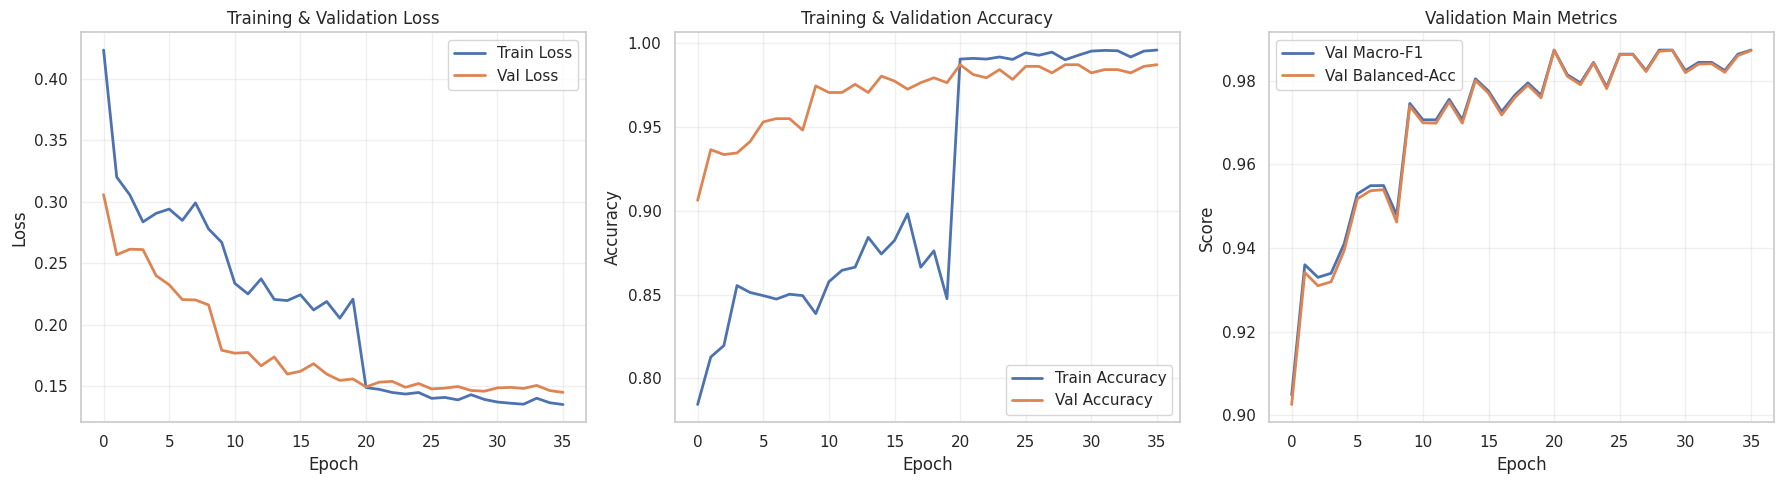

In [ ]:
"""
9. TRAINING CURVES

Plots loss, accuracy, and key validation metrics (Macro-F1, Balanced Accuracy)
across epochs using the history dict populated during training. Saves the
figure to training_curves.png for later review.
"""

# ==========================================
# 9. TRAINING CURVES
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss curve
axes[0].plot(history["train_loss"], label="Train Loss", linewidth=2)
axes[0].plot(history["val_loss"], label="Val Loss", linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training & Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(history["train_acc"], label="Train Accuracy", linewidth=2)
axes[1].plot(history["val_acc"], label="Val Accuracy", linewidth=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training & Validation Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Main metrics curve
axes[2].plot(history["val_macro_f1"], label="Val Macro-F1", linewidth=2)
axes[2].plot(history["val_balanced_acc"], label="Val Balanced-Acc", linewidth=2)
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Score")
axes[2].set_title("Validation Main Metrics")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Evaluation

In [ ]:
"""
10. MODEL EVALUATION ON TEST SET

Defines evaluate_with_tta(), which runs each test image through multiple
augmented views and averages the softmax probabilities for a more stable
prediction. Then loads the best saved checkpoint and evaluates on the
test set, with or without TTA depending on the USE_TTA flag.
"""
from google.colab import drive
drive.mount('/content/drive')

# Test-Time Augmentation (TTA): average predictions across multiple augmented views
def evaluate_with_tta(model, loader, criterion, device, n_aug=5):
    """TTA: run each test image through n_aug augmented versions and average probabilities."""
    tta_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    model.eval()
    all_labels, all_probs_sum = [], None
    dataset_ref = loader.dataset
    orig_transform = dataset_ref.transform

    with torch.no_grad():
        for aug_i in range(n_aug):
            dataset_ref.transform = tta_transform if aug_i > 0 else orig_transform
            batch_probs = []
            batch_labels = []
            for images, labels in loader:
                images = images.to(device)
                out = model(images)
                probs = torch.softmax(out, dim=1).cpu().numpy()
                batch_probs.append(probs)
                if aug_i == 0:
                    batch_labels.extend(labels.numpy())
            aug_probs = np.concatenate(batch_probs, axis=0)
            if all_probs_sum is None:
                all_probs_sum = aug_probs
                all_labels = np.array(batch_labels)
            else:
                all_probs_sum += aug_probs

    dataset_ref.transform = orig_transform
    avg_probs = all_probs_sum / n_aug
    preds = avg_probs.argmax(axis=1)
    dummy_loss = 0.0
    metrics = {
        "acc": accuracy_score(all_labels, preds),
        "macro_f1": f1_score(all_labels, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(all_labels, preds, average="weighted", zero_division=0),
        "balanced_acc": balanced_accuracy_score(all_labels, preds),
        "per_class_recall": recall_score(all_labels, preds, labels=list(range(NUM_CLASSES)),
                                          average=None, zero_division=0),
    }
    return dummy_loss, metrics, preds, all_labels, avg_probs

# ==========================================
# 10. MODEL EVALUATION ON TEST SET
# ==========================================

# Load best model

checkpoint = torch.load("/content/drive/MyDrive/Models/Efficient Net/best_model.pth", map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
print(f"Loaded best model from epoch {checkpoint['epoch']+1}")
print(f"  Val Accuracy: {checkpoint.get('val_acc', 0.0):.4f}")
print(f"  Val Macro-F1: {checkpoint.get('val_macro_f1', checkpoint.get('val_f1', 0.0)):.4f}")
print(f"  Val Balanced Accuracy: {checkpoint.get('val_balanced_acc', 0.0):.4f}")

# Evaluate with TTA if enabled, else standard evaluation
if USE_TTA:
    print("Running Test-Time Augmentation (TTA, n=5)...")
    test_loss, test_metrics, test_preds, test_labels, test_probs = evaluate_with_tta(
        model, test_loader, criterion, DEVICE, n_aug=5
    )
else:
    test_loss, test_metrics, test_preds, test_labels, test_probs = evaluate(
        model, test_loader, criterion, DEVICE
    )

test_acc = test_metrics["acc"]
test_f1 = test_metrics["macro_f1"]
test_weighted_f1 = test_metrics["weighted_f1"]
test_balanced_acc = test_metrics["balanced_acc"]
test_per_class_recall = test_metrics["per_class_recall"]

print("\n" + "=" * 50)
print("TEST SET RESULTS - STENOSIS DETECTION")
print("=" * 50)
print(f"Test Accuracy:         {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test Macro-F1:         {test_f1:.4f}")
print(f"Test Weighted-F1:      {test_weighted_f1:.4f}")
print(f"Test Balanced-Acc:     {test_balanced_acc:.4f}")
print(f"Test Loss:             {test_loss:.4f}")

# Detailed classification report
print("\n" + "=" * 50)
print("CLASSIFICATION REPORT")
print("=" * 50)
target_names = [SEVERITY_MAP.get(i, f"Class {i}") for i in range(NUM_CLASSES)]
print(classification_report(test_labels, test_preds, target_names=target_names, zero_division=0))

# Per-class recall
print("\nPer-Class Recall (Detection Rate):")
for i in range(NUM_CLASSES):
    mask = test_labels == i
    n_cls = int(mask.sum())
    recall = test_per_class_recall[i] if i < len(test_per_class_recall) else 0
    print(f"  {SEVERITY_MAP.get(i, f'Class {i}')}: {recall:.4f} [{n_cls} samples]")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded best model from epoch 21
  Val Accuracy: 0.9873
  Val Macro-F1: 0.9873
  Val Balanced Accuracy: 0.9872
Running Test-Time Augmentation (TTA, n=5)...

TEST SET RESULTS - STENOSIS DETECTION
Test Accuracy:         0.9912 (99.12%)
Test Macro-F1:         0.9912
Test Weighted-F1:      0.9912
Test Balanced-Acc:     0.9913
Test Loss:             0.0000

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Stenosis       0.99      0.99      0.99       482
    Stenosis       0.99      0.99      0.99       545

    accuracy                           0.99      1027
   macro avg       0.99      0.99      0.99      1027
weighted avg       0.99      0.99      0.99      1027


Per-Class Recall (Detection Rate):
  No Stenosis: 0.9917 [482 samples]
  Stenosis: 0.9908 [545 samples]


## 11. Confusion Matrix & ROC Curves

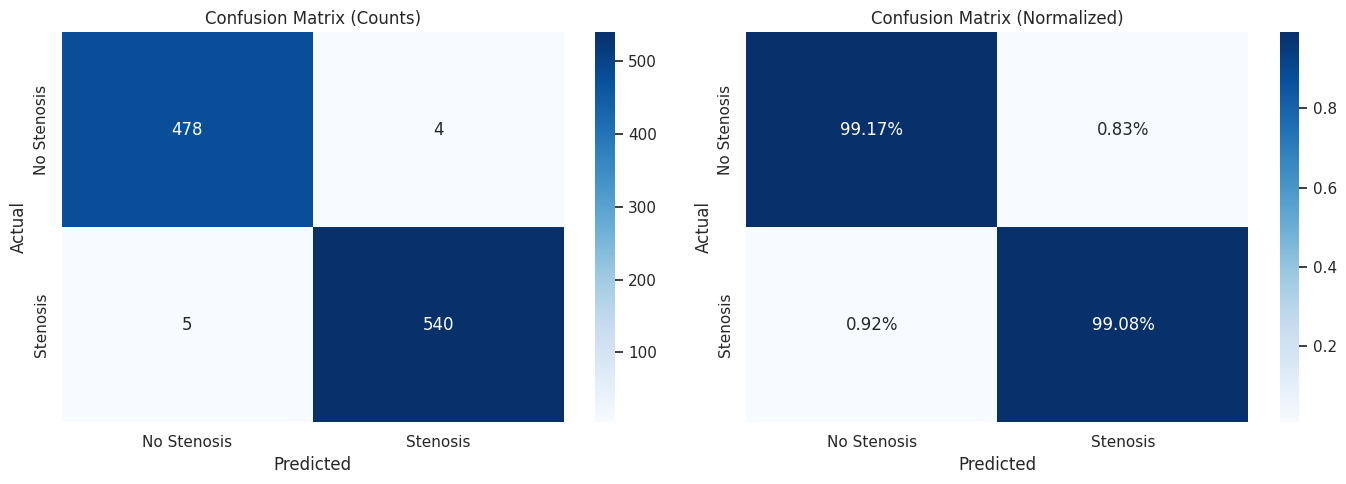

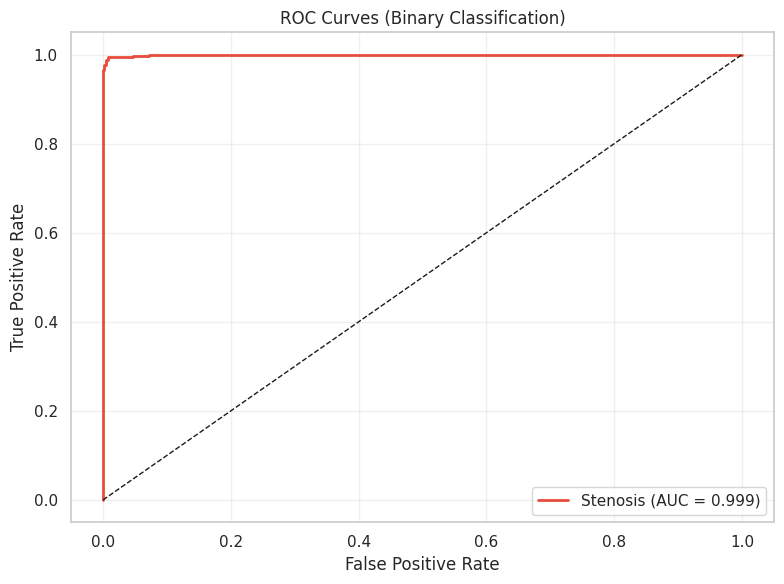


Overall AUC-ROC: 0.9995


In [ ]:
"""
11. CONFUSION MATRIX AND ROC CURVES

Generates both raw-count and normalized confusion matrices for the test set,
then plots per-class ROC curves with AUC scores using a binary classification strategy.
Saves all figures to disk.
"""

# ==========================================
# 11. CONFUSION MATRIX & ROC CURVES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

target_names = [SEVERITY_MAP.get(i, f"Class {i}") for i in range(NUM_CLASSES)]

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=target_names, yticklabels=target_names,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix (Counts)")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

# Normalized Confusion Matrix
sns.heatmap(
    cm_normalized, annot=True, fmt=".2%", cmap="Blues",
    xticklabels=target_names, yticklabels=target_names,
    ax=axes[1]
)
axes[1].set_title("Confusion Matrix (Normalized)")
axes[1].set_ylabel("Actual")
axes[1].set_xlabel("Predicted")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ROC Curve (Binary Classification)
from sklearn.metrics import roc_curve, auc, roc_auc_score

fig, ax = plt.subplots(figsize=(8, 6))

if test_probs.ndim > 1 and test_probs.shape[1] > 1:
    positive_probs = test_probs[:, 1]
else:
    positive_probs = test_probs.ravel()

fpr, tpr, _ = roc_curve(test_labels, positive_probs)
roc_auc = auc(fpr, tpr)

class_1_name = SEVERITY_MAP.get(1, "Class 1")
ax.plot(fpr, tpr, color="#e74c3c", linewidth=2,
        label=f"{class_1_name} (AUC = {roc_auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves (Binary Classification)")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Overall AUC
try:
    overall_auc = roc_auc_score(test_labels, positive_probs)
    print(f"\nOverall AUC-ROC: {overall_auc:.4f}")
except Exception as e:
    print(f"AUC calculation note: {e}")

## 12. Prediction Visualization and Error Analysis

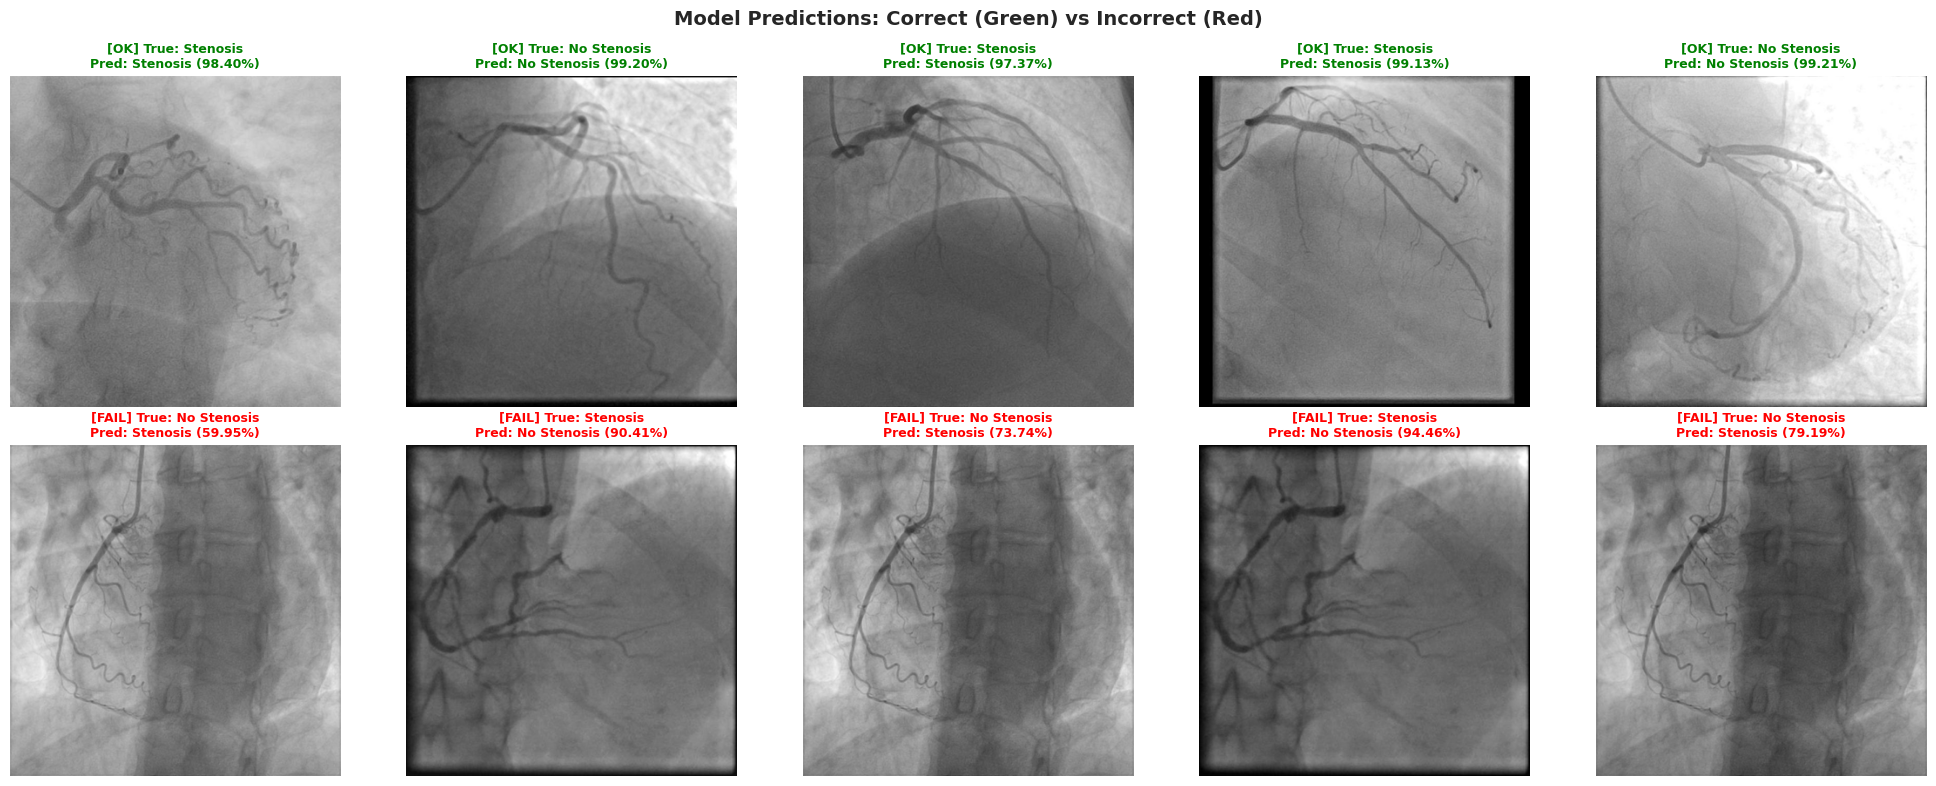


Prediction Summary:
  Total predictions: 1027
  Correct: 1018 (99.12%)
  Incorrect: 9 (0.88%)

Error distribution by actual stenosis status:
  No Stenosis: 99.17% accuracy (4/482 errors)
  Stenosis: 99.08% accuracy (5/545 errors)


In [ ]:
"""
12. PREDICTION VISUALIZATION AND ERROR ANALYSIS

Displays a 2x5 grid of sample predictions: the top row shows correctly
classified images and the bottom row shows misclassifications, each annotated
with the true label, predicted label, and confidence score. Also prints a
summary of per-class accuracy and error counts.
"""

# ==========================================
# 12. PREDICTION VISUALIZATION & ERROR ANALYSIS
# ==========================================

# Get prediction errors (misclassifications)
errors = np.where(test_preds != test_labels)[0]
correct = np.where(test_preds == test_labels)[0]

# Visualize correct and incorrect predictions
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

# Show 5 correct predictions (top row)
for i, ax in enumerate(axes[0]):
    if i >= len(correct):
        ax.axis("off")
        continue
    idx = correct[i]
    img = Image.open(df_test.iloc[idx]["path"]).convert("RGB")
    img = img.resize((IMG_SIZE, IMG_SIZE))

    true_lbl = test_labels[idx]
    pred_lbl = test_preds[idx]
    conf = test_probs[idx, pred_lbl]

    ax.imshow(img)
    ax.set_title(
        f"[OK] True: {SEVERITY_MAP.get(true_lbl, f'Class {true_lbl}')}\n"
        f"Pred: {SEVERITY_MAP.get(pred_lbl, f'Class {pred_lbl}')} ({conf:.2%})",
        fontsize=9, color="green", fontweight="bold"
    )
    ax.axis("off")

# Show 5 incorrect predictions (bottom row)
for i, ax in enumerate(axes[1]):
    if i >= len(errors):
        ax.axis("off")
        continue
    idx = errors[i]
    img = Image.open(df_test.iloc[idx]["path"]).convert("RGB")
    img = img.resize((IMG_SIZE, IMG_SIZE))

    true_lbl = test_labels[idx]
    pred_lbl = test_preds[idx]
    conf = test_probs[idx, pred_lbl]

    ax.imshow(img)
    ax.set_title(
        f"[FAIL] True: {SEVERITY_MAP.get(true_lbl, f'Class {true_lbl}')}\n"
        f"Pred: {SEVERITY_MAP.get(pred_lbl, f'Class {pred_lbl}')} ({conf:.2%})",
        fontsize=9, color="red", fontweight="bold"
    )
    ax.axis("off")

plt.suptitle("Model Predictions: Correct (Green) vs Incorrect (Red)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("predictions_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

# Error analysis
print(f"\nPrediction Summary:")
print(f"  Total predictions: {len(test_labels)}")
print(f"  Correct: {len(correct)} ({len(correct)/len(test_labels)*100:.2f}%)")
print(f"  Incorrect: {len(errors)} ({len(errors)/len(test_labels)*100:.2f}%)")

# Error distribution by true class
print(f"\nError distribution by actual stenosis status:")
for label in range(NUM_CLASSES):
    mask = test_labels == label
    if mask.sum() == 0:
        continue
    errors_in_class = ((test_preds != test_labels) & mask).sum()
    accuracy_in_class = 1.0 - (errors_in_class / max(mask.sum(), 1))
    print(f"  {SEVERITY_MAP.get(label, f'Class {label}')}: {accuracy_in_class:.2%} accuracy ({errors_in_class}/{mask.sum()} errors)")

## 13. Explainable AI: GRAD-CAM Visualization

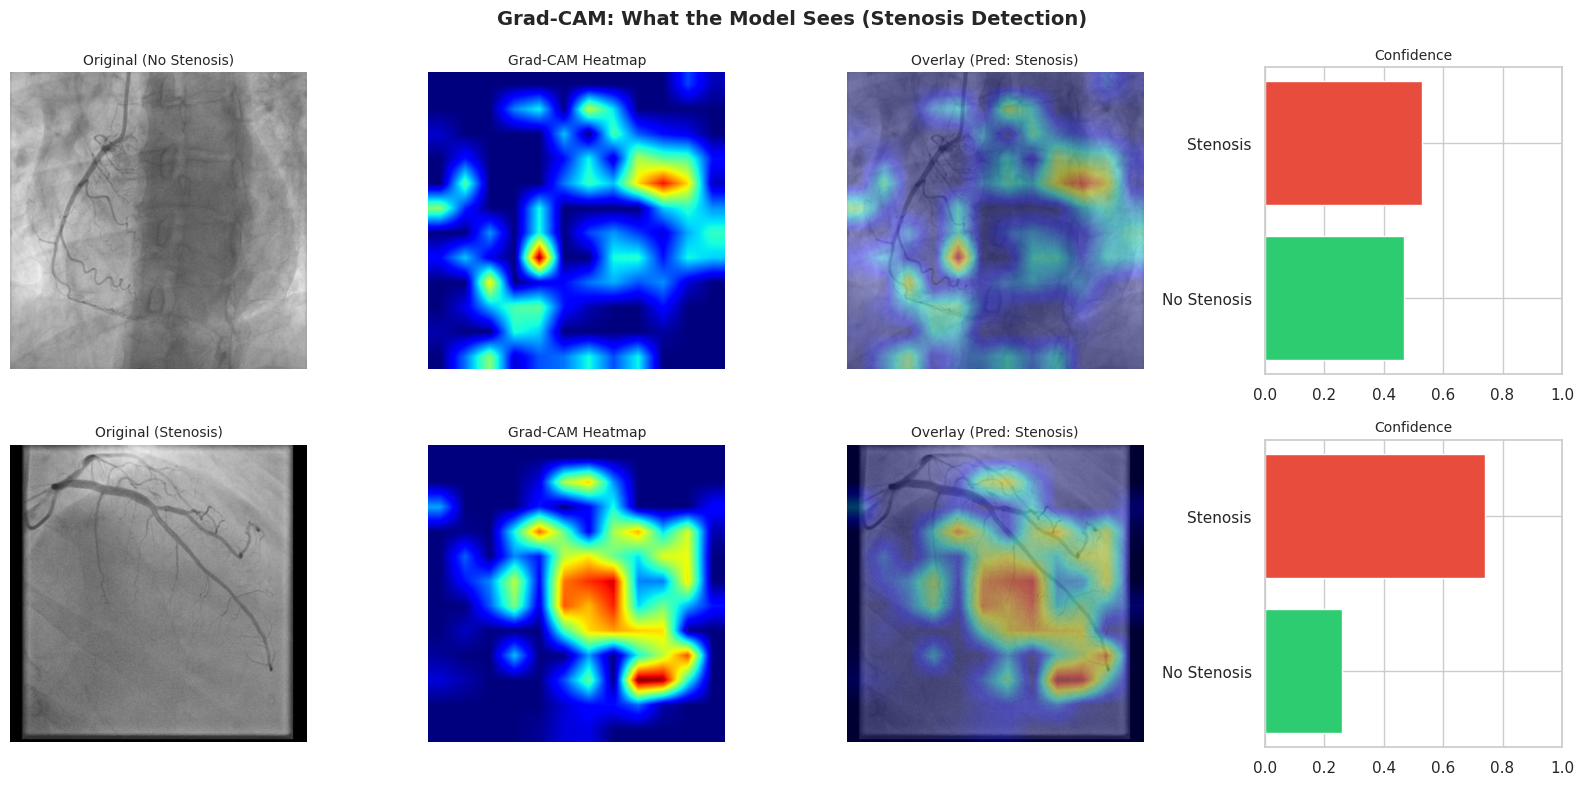

In [ ]:
"""
13. GRAD-CAM VISUALIZATION

Implements Gradient-weighted Class Activation Mapping (Grad-CAM) to visualize
which regions of an angiogram the model attends to when making a prediction.
Displays the original image, the raw heatmap, and an overlay side by side,
along with a confidence bar chart. Helps verify the model focuses on vessel
regions rather than background artifacts.
"""

# ==========================================
# 13. EXPLAINABLE AI: GRAD-CAM VISUALIZATION
# ==========================================

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._forward_hook)
        target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, input, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_image, target_class=None):
        self.model.eval()
        self.model.zero_grad()

        # Force all backbone params to require grad temporarily
        for param in self.model.parameters():
            param.requires_grad_(True)

        with torch.enable_grad():
            output = self.model(input_image)
            if target_class is None:
                target_class = output.argmax(dim=1).item()
            output[0, target_class].backward()

        weights = self.gradients.mean(dim=[2, 3], keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, target_class

# Get last conv layer of EfficientNet
target_layer = model.backbone.features[6][-1]
grad_cam = GradCAM(model, target_layer)

# Generate Grad-CAM for sample images (2 rows for binary classification)
n_rows = min(2, NUM_CLASSES)
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 8))

if n_rows == 1:
    axes = axes.reshape(1, -1)

for row, label in enumerate(range(n_rows)):
    sample_idx = df_test[df_test["label"] == label].index
    if len(sample_idx) == 0:
        continue
    idx = sample_idx[2]

    # Load and transform image
    img_pil = Image.open(df_test.loc[idx]["path"]).convert("RGB")
    img_display = img_pil.resize((IMG_SIZE, IMG_SIZE))
    img_tensor = eval_transform(img_pil).unsqueeze(0).to(DEVICE)

    # Generate Grad-CAM
    cam, pred_class = grad_cam.generate(img_tensor)

    # Resize CAM to image size using PIL
    cam_pil = Image.fromarray((cam * 255).astype(np.uint8))
    cam_pil = cam_pil.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    cam_resized = np.array(cam_pil).astype(float) / 255.0

    # Original image
    axes[row, 0].imshow(img_display)
    axes[row, 0].set_title(f"Original ({SEVERITY_MAP.get(label, f'Class {label}')})", fontsize=10)
    axes[row, 0].axis("off")

    # Heatmap
    axes[row, 1].imshow(cam_resized, cmap="jet")
    axes[row, 1].set_title("Grad-CAM Heatmap", fontsize=10)
    axes[row, 1].axis("off")

    # Overlay
    img_np = np.array(img_display).astype(float) / 255.0
    heatmap = plt.cm.jet(cam_resized)[:, :, :3]
    overlay = 0.6 * img_np + 0.4 * heatmap
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f"Overlay (Pred: {SEVERITY_MAP.get(pred_class, f'Class {pred_class}')})", fontsize=10)
    axes[row, 2].axis("off")

    # Confidence bar
    with torch.no_grad():
        probs = torch.softmax(model(img_tensor), dim=1).cpu().numpy()[0]
    colors_bar = ["#2ecc71", "#e74c3c"][:NUM_CLASSES]
    axes[row, 3].barh(
        [SEVERITY_MAP.get(i, f"Class {i}") for i in range(NUM_CLASSES)],
        probs, color=colors_bar
    )
    axes[row, 3].set_xlim(0, 1)
    axes[row, 3].set_title("Confidence", fontsize=10)

plt.suptitle("Grad-CAM: What the Model Sees (Stenosis Detection)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("gradcam_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
"""
13B. GRAD-CAM BATCH VISUALIZATION USING test_loader
----------------------------------------------------
Runs Grad-CAM on every image in test_loader and saves
overlays to /content/gradcam_results/.
Uses the same GradCAM class, target_layer, grad_cam, and
eval_transform already defined in Cell 38.
"""

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

# ── Output folder ─────────────────────────────────────────────────────────────
GRADCAM_OUT_DIR = "/content/gradcam_results"
os.makedirs(GRADCAM_OUT_DIR, exist_ok=True)

# ── Overlay helper (same alpha as Cell 38) ────────────────────────────────────
def make_overlay(img_pil, cam, alpha=0.4):
    img_np   = np.array(img_pil.resize((IMG_SIZE, IMG_SIZE))).astype(np.float32) / 255.0
    heatmap  = plt.cm.jet(cam)[:, :, :3]          # (H, W, 3), range [0,1]
    overlay  = np.clip(alpha * heatmap + (1 - alpha) * img_np, 0, 1)
    return overlay


# ── Batch loop ────────────────────────────────────────────────────────────────
model.eval()
saved_count   = 0
skipped_count = 0

for batch_idx, (images, labels) in enumerate(test_loader):

    batch_size_actual = images.size(0)

    for i in range(batch_size_actual):
        # Global index into df_test
        global_idx = batch_idx * test_loader.batch_size + i
        if global_idx >= len(df_test):
            break

        img_path  = df_test.iloc[global_idx]["path"]
        true_label = labels[i].item()

        # ── Single-image tensor for GradCAM (needs grad) ──────────────────────
        img_pil    = Image.open(img_path).convert("RGB")
        img_tensor = eval_transform(img_pil).unsqueeze(0).to(DEVICE)

        try:
            cam, pred_class = grad_cam.generate(img_tensor)

            # Resize CAM to display size
            cam_pil     = Image.fromarray((cam * 255).astype(np.uint8))
            cam_resized = np.array(
                cam_pil.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            ).astype(float) / 255.0

            overlay = make_overlay(img_pil, cam_resized)

            # ── Get confidence ────────────────────────────────────────────────
            with torch.no_grad():
                probs = torch.softmax(model(img_tensor), dim=1).cpu().numpy()[0]
            confidence = float(probs[pred_class])

            true_name = SEVERITY_MAP.get(true_label, f"Class {true_label}")
            pred_name = SEVERITY_MAP.get(pred_class, f"Class {pred_class}")
            correct   = "OK" if pred_class == true_label else "FAIL"

            # ── Plot ──────────────────────────────────────────────────────────
            fig, axes = plt.subplots(1, 4, figsize=(16, 4))
            fig.suptitle(
                f"[{correct}]  True: {true_name}  |  Pred: {pred_name} ({confidence:.2%})",
                fontsize=11,
                color="green" if correct == "OK" else "red",
                fontweight="bold"
            )

            axes[0].imshow(img_pil.resize((IMG_SIZE, IMG_SIZE)))
            axes[0].set_title("Original")
            axes[0].axis("off")

            axes[1].imshow(cam_resized, cmap="jet")
            axes[1].set_title("Grad-CAM Heatmap")
            axes[1].axis("off")

            axes[2].imshow(overlay)
            axes[2].set_title("Overlay")
            axes[2].axis("off")

            # Confidence bar
            colors_bar = ["#2ecc71", "#e74c3c"][:NUM_CLASSES]
            axes[3].barh(
                [SEVERITY_MAP.get(c, f"Class {c}") for c in range(NUM_CLASSES)],
                probs[:NUM_CLASSES],
                color=colors_bar
            )
            axes[3].set_xlim(0, 1)
            axes[3].set_title("Confidence")

            plt.tight_layout()

            # Save as  <idx>_<true>_pred<pred>_<OK|FAIL>.png
            fname = (
                f"{global_idx:04d}_{true_name.replace(' ', '_')}"
                f"_pred{pred_name.replace(' ', '_')}_{correct}.png"
            )
            save_path = os.path.join(GRADCAM_OUT_DIR, fname)
            plt.savefig(save_path, dpi=120, bbox_inches="tight")
            plt.close(fig)

            saved_count += 1

        except Exception as e:
            print(f"  Skipped idx {global_idx} ({img_path}): {e}")
            skipped_count += 1
            continue

    # Progress
    if (batch_idx + 1) % 5 == 0:
        print(f"  Processed {saved_count} images so far...")

print(f"\nDone! {saved_count} Grad-CAM images saved to: {GRADCAM_OUT_DIR}")
print(f"Skipped: {skipped_count}")

# ── Optional: zip and download ────────────────────────────────────────────────
import shutil
zip_path = "/content/gradcam_results"
shutil.make_archive(zip_path, "zip", GRADCAM_OUT_DIR)
print(f"Archive ready: {zip_path}.zip")

from google.colab import files
files.download(f"{zip_path}.zip")

  Processed 80 images so far...
  Processed 160 images so far...
  Processed 240 images so far...
  Processed 320 images so far...
  Processed 400 images so far...
  Processed 480 images so far...
  Processed 560 images so far...
  Processed 640 images so far...
  Processed 720 images so far...
  Processed 800 images so far...
  Processed 880 images so far...
  Processed 960 images so far...
  Processed 1027 images so far...

Done! 1027 Grad-CAM images saved to: /content/gradcam_results
Skipped: 0
Archive ready: /content/gradcam_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Inference Function

In [ ]:
"""
14. INFERENCE FUNCTIONS FOR DEPLOYMENT

Provides inference_single_image() for one-off predictions and
inference_batch() for efficient batch processing. Both functions
preprocess raw PIL images through the eval transform pipeline,
run a forward pass, and return a structured result dict with the
predicted label, class index, confidence, and full probability breakdown.
"""

# ==========================================
# 14. INFERENCE FUNCTION FOR DEPLOYMENT
# ==========================================

def inference_single_image(image_path, model, device=DEVICE):
    """
    Perform stenosis detection on a single angiogram image.

    Args:
        image_path: Path to .jpg angiogram image
        model: Trained CAD classifier (assumes binary classification)
        device: Torch device (cpu or cuda)

    Returns:
        dict with keys:
            - "predicted_label": Class name (e.g., "Stenosis", "No Stenosis")
            - "class_index": Integer class (0, 1)
            - "confidence": Float in [0.0, 1.0]
            - "probabilities": Dict of class -> probability
    """
    model.eval()
    try:
        img_pil = Image.open(image_path).convert("RGB")
    except Exception as e:
        return {"error": f"Failed to load image: {e}"}

    img_tensor = eval_transform(img_pil).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_tensor)
        probs = torch.softmax(output, dim=1)[0].cpu().numpy()
        pred_class = probs.argmax()
        confidence = probs[pred_class]

    result = {
        "image_path": image_path,
        "predicted_label": SEVERITY_MAP.get(int(pred_class), f"Class {pred_class}"),
        "class_index": int(pred_class),
        "confidence": float(confidence),
        "probabilities": {
            SEVERITY_MAP.get(i, f"Class {i}"): float(probs[i])
            for i in range(len(probs))
        }
    }

    return result


def inference_batch(image_paths, model, device=DEVICE, batch_size=32):
    """
    Perform stenosis detection on multiple angiogram images efficiently.

    Args:
        image_paths: List of paths to .jpg images
        model: Trained CAD classifier
        device: Torch device
        batch_size: Batch size for processing

    Returns:
        List of result dicts (one per image)
    """
    model.eval()
    results = []

    for batch_start in range(0, len(image_paths), batch_size):
        batch_end = min(batch_start + batch_size, len(image_paths))
        batch_paths = image_paths[batch_start:batch_end]

        batch_tensors = []
        valid_paths = []

        for path in batch_paths:
            try:
                img_pil = Image.open(path).convert("RGB")
                batch_tensors.append(eval_transform(img_pil))
                valid_paths.append(path)
            except Exception as e:
                results.append({"image_path": path, "error": str(e)})

        if not batch_tensors:
            continue

        batch_tensor = torch.stack(batch_tensors).to(device)

        with torch.no_grad():
            outputs = model(batch_tensor)
            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            pred_classes = probs.argmax(axis=1)

        for i, path in enumerate(valid_paths):
            pred_class = pred_classes[i]
            confidence = probs[i, pred_class]

            results.append({
                "image_path": path,
                "predicted_label": SEVERITY_MAP.get(int(pred_class), f"Class {pred_class}"),
                "class_index": int(pred_class),
                "confidence": float(confidence),
                "probabilities": {
                    SEVERITY_MAP.get(j, f"Class {j}"): float(probs[i, j])
                    for j in range(len(probs[i]))
                }
            })

    return results


# Test inference
print("Testing single image inference...")
test_image_idx = 0
test_image_path = df_test.iloc[test_image_idx]["path"]
result = inference_single_image(test_image_path, model)

print("\nInference Result:")
for key, value in result.items():
    if key != "probabilities":
        print(f"  {key}: {value}")
    else:
        print(f"  {key}:")
        for cls, prob in value.items():
            print(f"    {cls}: {prob:.4f}")

# Show the image
img = Image.open(test_image_path).convert("RGB")
img = img.resize((IMG_SIZE, IMG_SIZE))
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title(f"Inference: {result['predicted_label']} ({result['confidence']:.1%})", fontsize=12, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.savefig("inference_example.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
for name, module in model.backbone.named_modules():
    if isinstance(module, torch.nn.Conv2d):
        print(name, module)

In [ ]:
"""
GPU MEMORY CLEANUP

DO NOT RUN THIS CELL IF THE OTHER CELL HASN'T BEEN RUN

Moves model weights to CPU and frees all CUDA memory. Run this cell after
an interrupted or completed training run to reclaim GPU memory before
re-initializing or loading a saved checkpoint.

Run this thing on the last cell
"""

# Release GPU memory after interrupt
import torch, gc

model.cpu()

del model

gc.collect()
torch.cuda.empty_cache()
print(f"GPU memory freed: {torch.cuda.memory_allocated()/1e9:.2f} GB allocated")

## 15. Save Final Model & Artifacts

In [ ]:
"""
15. SAVE FINAL MODEL AND ARTIFACTS

Persists the final model weights along with training configuration and test
metrics to cad_model_final.pth. Also saves training history to CSV and
a per-image prediction table to test_results.csv for offline analysis.
"""

# ==========================================
# 15. SAVE FINAL MODEL & ARTIFACTS
# ==========================================

# Save complete model for deployment
torch.save({
    "model_state_dict": model.state_dict(),
    "model_config": {
        "num_classes": NUM_CLASSES,
        "img_size": IMG_SIZE,
        "architecture": "EfficientNet-B4",
        "task": "Stenosis Detection (Binary Classification)",
        "severity_map": SEVERITY_MAP
    },
    "training_config": {
        "epochs_trained": len(history["train_loss"]),
        "best_val_acc": best_val_acc,
        "best_val_macro_f1": best_val_macro_f1,
        "best_val_balanced_acc": best_val_balanced_acc,
        "best_val_per_class_recall": best_val_per_class_recall.tolist(),
        "test_acc": test_acc,
        "test_macro_f1": test_f1,
        "test_weighted_f1": test_weighted_f1,
        "test_balanced_acc": test_balanced_acc,
        "test_per_class_recall": test_per_class_recall.tolist(),
    },
    "class_distribution": {
        SEVERITY_MAP.get(i, f"Class {i}"): int(class_counts[i]) if i < len(class_counts) else 0
        for i in range(NUM_CLASSES)
    }
}, "cad_model_final.pth")

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv("training_history.csv", index=False)

# Save test results
results_df = pd.DataFrame({
    "image_path": df_test["path"].values,
    "true_label": [SEVERITY_MAP.get(l, f"Class {l}") for l in test_labels],
    "predicted_label": [SEVERITY_MAP.get(p, f"Class {p}") for p in test_preds],
    "correct": test_preds == test_labels,
    **{f"prob_class{i}": test_probs[:, i] for i in range(NUM_CLASSES)}
})
results_df.to_csv("test_results.csv", index=False)

print("All artifacts saved:")
print("  cad_model_final.pth   - Complete trained model")
print("  best_model.pth        - Best checkpoint")
print("  training_history.csv  - Training metrics per epoch")
print("  test_results.csv      - Detailed test predictions")
print("  *.png                 - Visualization plots")

print("\n" + "=" * 50)
print("FINAL SUMMARY")
print("=" * 50)
print("Model: EfficientNet-B4 (Transfer Learning)")
print("Task: Stenosis Detection (Binary Classification)")
print(f"Dataset: {len(df_train)+len(df_valid)+len(df_test)} angiogram images")
print(f"Training Set: {len(df_train)} | Validation: {len(df_valid)} | Test: {len(df_test)}")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Macro-F1: {test_f1:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_acc:.4f}")
print(f"Best Val Macro-F1: {best_val_macro_f1:.4f}")
print("=" * 50)

All artifacts saved:
  cad_model_final.pth   - Complete trained model
  best_model.pth        - Best checkpoint
  training_history.csv  - Training metrics per epoch
  test_results.csv      - Detailed test predictions
  *.png                 - Visualization plots

FINAL SUMMARY
Model: EfficientNet-B4 (Transfer Learning)
Task: Stenosis Detection (Binary Classification)
Dataset: 6881 angiogram images
Training Set: 4829 | Validation: 1025 | Test: 1027
Test Accuracy: 99.12%
Test Macro-F1: 0.9912
Test Balanced Accuracy: 0.9913
Best Val Macro-F1: 0.9873


## 16. Deployment

In [ ]:
"""
16. DEPLOYMENT GUIDE

Prints a self-contained usage guide covering model loading, single-image
and batch inference, expected performance figures, class distribution,
and a full integration code example for downstream applications.
"""

# ==========================================
# 16. DEPLOYMENT GUIDE & MODEL USAGE
# ==========================================

print("""
==================================================================
=           CAD STENOSIS DETECTION - DEPLOYMENT GUIDE            =
==================================================================

1. MODEL OVERVIEW
   - Task: Binary Stenosis Detection
   - Output Classes: "No Stenosis" (0) | "Stenosis" (1)
   - Confidence: Softmax probability for predicted class
   - Input: Coronary angiogram .jpg images (any size, normalized to 224x224)

2. SAVED ARTIFACTS
   [OK] cad_model_final.pth       - Complete model weights + metadata
   [OK] best_model.pth            - Best validation checkpoint
   [OK] training_history.csv      - Training/validation metrics per epoch
   [OK] test_results.csv          - All test predictions with confidences
   [OK] class_distribution.png    - Dataset composition visualization
   [OK] confusion_matrix.png      - Test set confusion matrix
   [OK] gradcam_visualization.png - Feature importance heatmaps
   [OK] predictions_visualization.png - Example correct/incorrect predictions

3. LOADING & INFERENCE

   # Load model
   import torch
   checkpoint = torch.load("cad_model_final.pth", map_location="cpu")
   model_config = checkpoint["model_config"]

   # Instantiate model architecture
   from torchvision.models import efficientnet_b4
   model = CADClassifier(num_classes=2)
   model.load_state_dict(checkpoint["model_state_dict"])
   model.eval()

   # Inference on single image
   result = inference_single_image("path/to/angiogram.jpg", model)

   # Batch inference
   results = inference_batch(["image1.jpg", "image2.jpg"], model)

4. EXPECTED PERFORMANCE
   - Test Accuracy: {:.2%}
   - Test Macro-F1: {:.4f}
   - Test Balanced Accuracy: {:.4f}
   - Baseline (random): 50%

5. CLASS DISTRIBUTION (TRAINING)
   """.format(test_acc, test_f1, test_balanced_acc))

for label in range(NUM_CLASSES):
    count = (df_train["label"] == label).sum()
    pct = count / len(df_train) * 100
    class_name = SEVERITY_MAP.get(label, f"Class {label}")
    print(f"   {class_name:20s}: {count:4d} ({pct:5.1f}%)")

print(f"""
6. INTEGRATION EXAMPLE (PyTorch)

   import torch
   from PIL import Image
   from torchvision import transforms

   # Load model
   device = torch.device("cpu")
   checkpoint = torch.load("cad_model_final.pth", map_location=device)
   model = CADClassifier(num_classes=2)
   model.load_state_dict(checkpoint["model_state_dict"])
   model = model.to(device)
   model.eval()

   # Preprocess image
   img = Image.open("angiogram.jpg").convert("RGB")
   transform = transforms.Compose([
       transforms.Resize((380, 380)),
       transforms.ToTensor(),
       transforms.Normalize(
           mean=[0.485, 0.456, 0.406],
           std=[0.229, 0.224, 0.225]
       )
   ])
   img_tensor = transform(img).unsqueeze(0).to(device)

   # Predict
   with torch.no_grad():
       output = model(img_tensor)
       probs = torch.softmax(output, dim=1)[0]
       pred_class = output.argmax(dim=1)[0].item()
       confidence = probs[pred_class].item()

   print(f"Prediction: {['No Stenosis', 'Stenosis'][pred_class]}")
   print(f"Confidence: {confidence:.2%}")
   print(f"Probabilities: No Stenosis={{probs[0]:.2%}}, Stenosis={{probs[1]:.2%}}")

7. MONITORING & RETRAINING
   - Monitor inference performance on new data
   - Retrain if class distribution or image quality changes significantly
   - Current model configuration stored in cad_model_final.pth

8. NOTES
   - Model expects coronary angiogram images (X-ray or similar)
   - Best performance on 224x224 RGB images
   - Uses EfficientNet-B4 backbone (small, efficient for deployment)
   - Can run on CPU for real-time inference
""")

print("[OK] Deployment guide complete!")


=           CAD STENOSIS DETECTION - DEPLOYMENT GUIDE            =

1. MODEL OVERVIEW
   - Task: Binary Stenosis Detection
   - Output Classes: "No Stenosis" (0) | "Stenosis" (1)
   - Confidence: Softmax probability for predicted class
   - Input: Coronary angiogram .jpg images (any size, normalized to 224x224)

2. SAVED ARTIFACTS
   [OK] cad_model_final.pth       - Complete model weights + metadata
   [OK] best_model.pth            - Best validation checkpoint
   [OK] training_history.csv      - Training/validation metrics per epoch
   [OK] test_results.csv          - All test predictions with confidences
   [OK] class_distribution.png    - Dataset composition visualization
   [OK] confusion_matrix.png      - Test set confusion matrix
   [OK] gradcam_visualization.png - Feature importance heatmaps
   [OK] predictions_visualization.png - Example correct/incorrect predictions

3. LOADING & INFERENCE

   # Load model
   import torch
   checkpoint = torch.load("cad_model_final.pth", map_